In [1]:
import pandas as pd

cluster1_enrich = pd.read_csv('./results/enrichment/cluster1_enrichment.csv')
print(cluster1_enrich.columns.tolist())
print(cluster1_enrich.head())

['Category', 'Term', 'Count', 'List Total', 'Pop Hits', 'Pop Total', 'P-Value', 'Benjamini', 'Fold Enrichment', 'Bonferroni', 'FDR', 'Fisher Exact', 'User Ids']
                   Category           Term  Count  List Total  Pop Hits  \
0  UP_KW_BIOLOGICAL_PROCESS     Cell cycle     92         154       692   
1          GOTERM_BP_DIRECT  cell division     71         179       433   
2          GOTERM_CC_DIRECT     chromosome     76         179       720   
3  UP_KW_BIOLOGICAL_PROCESS  Cell division     70         154       422   
4  UP_KW_BIOLOGICAL_PROCESS        Mitosis     62         154       294   

   Pop Total       P-Value     Benjamini  Fold Enrichment    Bonferroni  \
0      11605  1.810000e-72  6.860000e-71            10.02  6.860000e-71   
1      19512  2.700000e-69  2.310000e-66            17.87  2.310000e-66   
2      20808  5.530000e-62  1.190000e-59            12.27  1.190000e-59   
3      11605  4.250000e-59  8.070000e-58            12.50  1.610000e-57   
4      11605 

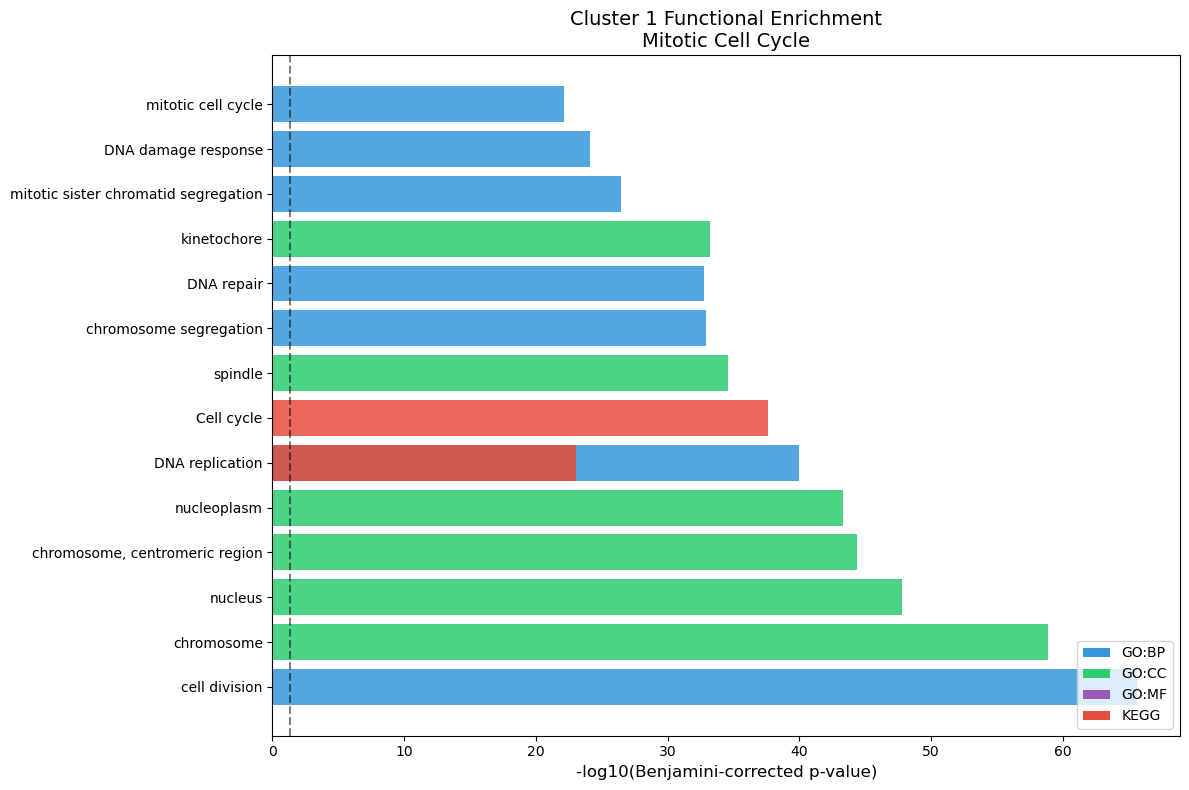


Records after category filter: 168
Category
GOTERM_BP_DIRECT    70
GOTERM_CC_DIRECT    49
GOTERM_MF_DIRECT    32
KEGG_PATHWAY        17
Name: count, dtype: int64

Top 15 terms:
            Category                                  Term  Count     Benjamini  Fold Enrichment
1   GOTERM_BP_DIRECT                         cell division     71  2.310000e-66            17.87
2   GOTERM_CC_DIRECT                            chromosome     76  1.190000e-59            12.27
5   GOTERM_CC_DIRECT                               nucleus    157  1.700000e-48             2.59
7   GOTERM_CC_DIRECT        chromosome, centromeric region     41  4.270000e-45            28.37
8   GOTERM_CC_DIRECT                           nucleoplasm    123  4.700000e-44             3.50
9   GOTERM_BP_DIRECT                       DNA replication     37  1.000000e-40            30.10
11      KEGG_PATHWAY                            Cell cycle     37  2.320000e-38            22.69
13  GOTERM_CC_DIRECT                          

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

cluster1_enrich = pd.read_csv('./results/enrichment/cluster1_enrichment.csv')

categories_keep = ['GOTERM_BP_DIRECT', 'GOTERM_CC_DIRECT', 
                   'GOTERM_MF_DIRECT', 'KEGG_PATHWAY']
filtered = cluster1_enrich[cluster1_enrich['Category'].isin(categories_keep)]
filtered = filtered.sort_values('P-Value').head(15)
filtered['-log10(FDR)'] = -np.log10(filtered['Benjamini'])

color_dict = {
    'GOTERM_BP_DIRECT': '#3498db',
    'GOTERM_CC_DIRECT': '#2ecc71',
    'GOTERM_MF_DIRECT': '#9b59b6',
    'KEGG_PATHWAY': '#e74c3c'
}
colors = [color_dict[cat] for cat in filtered['Category']]

plt.figure(figsize=(12, 8))
plt.barh(filtered['Term'], filtered['-log10(FDR)'], color=colors, alpha=0.85)
plt.xlabel('-log10(Benjamini-corrected p-value)', fontsize=12)
plt.title('Cluster 1 Functional Enrichment\nMitotic Cell Cycle', fontsize=14)
plt.axvline(x=-np.log10(0.05), color='black', linestyle='--', alpha=0.5)

legend_elements = [Patch(facecolor='#3498db', label='GO:BP'),
                   Patch(facecolor='#2ecc71', label='GO:CC'),
                   Patch(facecolor='#9b59b6', label='GO:MF'),
                   Patch(facecolor='#e74c3c', label='KEGG')]
plt.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.savefig('./figures/cluster1_enrichment.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary table
print(f"\nRecords after category filter: {len(cluster1_enrich[cluster1_enrich['Category'].isin(categories_keep)])}")
print(cluster1_enrich[cluster1_enrich['Category'].isin(categories_keep)]['Category'].value_counts())
print("\nTop 15 terms:")
print(filtered[['Category', 'Term', 'Count', 'Benjamini', 'Fold Enrichment']].to_string())